In [27]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict, Annotated
from dotenv import load_dotenv
from pydantic import BaseModel, Field
import operator

In [28]:
load_dotenv()

True

In [29]:
model = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

In [30]:
class evaluationSchema(BaseModel):
    feedback : str = Field(description="Feedback on the answer provided")
    score : int = Field(description="Score of the answer provided", ge=0, le= 10)
    


In [31]:
structured_model = model.with_structured_output(evaluationSchema)

In [32]:
class UPSCstate(TypedDict):
   essay : str
   langFeedback : str
   analysisFeedback : str
   clarityFeedback : str
   overallFeedback : str
   individualScores : Annotated[list[int], operator.add]  #add is a reducer function that will be used to combine the scores from the individual feedbacks
   avg_score : float


In [33]:
def evaluate_overall(state: UPSCstate) -> UPSCstate:
    #summary feedback
    overall_feedback = f"Language Feedback: {state['langFeedback']}\nAnalysis Feedback: {state['analysisFeedback']}\nClarity Feedback: {state['clarityFeedback']}"
    #avergae score
    avg_score = sum(state['individualScores']) / len(state['individualScores'])
    return {'overallFeedback': overall_feedback, 'avg_score': avg_score}

In [34]:
def evaluate_clarity(state: UPSCstate) -> UPSCstate:
    prompt = f"Evaluate the following essay for clarity quality and provide feedback and a score out of 10:\n\n{state['essay']}"
    result = structured_model.invoke(prompt)
    return {'clarityFeedback': result.feedback, 'individualScores': [result.score]}

In [35]:
def evaluate_analysis(state: UPSCstate) -> UPSCstate:
    prompt = f"Evaluate the following essay for analysis quality and provide feedback and a score out of 10:\n\n{state['essay']}"
    result = structured_model.invoke(prompt)
    return {'analysisFeedback': result.feedback, 'individualScores': [result.score]}

In [36]:
def evaluate_language(state: UPSCstate) -> UPSCstate:
    prompt = f"Evaluate the following essay for language quality and provide feedback and a score out of 10:\n\n{state['essay']}"
    result = structured_model.invoke(prompt)
    return {'langFeedback': result.feedback, 'individualScores': [result.score]}

In [37]:
graph = StateGraph(UPSCstate)
graph.add_node("evaluatelang", evaluate_language)
graph.add_node("evaluateanalysis", evaluate_analysis)
graph.add_node("evaluateclarity", evaluate_clarity)
graph.add_node("evaluateoverall", evaluate_overall)

In [38]:
graph.add_edge(START, "evaluatelang")
graph.add_edge(START, "evaluateanalysis")
graph.add_edge(START, "evaluateclarity")
graph.add_edge('evaluatelang', "evaluateoverall") 
graph.add_edge('evaluateanalysis', "evaluateoverall")
graph.add_edge('evaluateclarity', "evaluateoverall") 
graph.add_edge("evaluateoverall", END)

In [39]:
workflow = graph.compile()

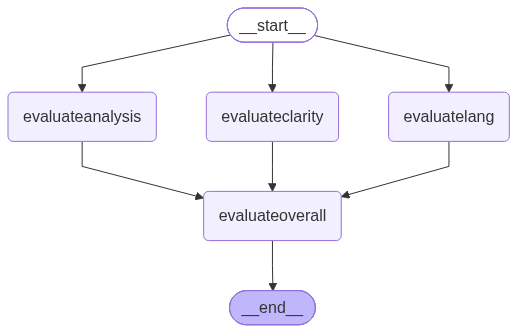

In [40]:
workflow

In [41]:
initial_state = {
    'essay': "The essay discusses the importance of environmental conservation and the role of individuals in how you are good what what is this now"}

In [42]:
workflow.invoke(initial_state)

{'essay': 'The essay discusses the importance of environmental conservation and the role of individuals in how you are good what what is this now',
 'langFeedback': 'The essay snippet is incomplete, incoherent, and abruptly breaks down into nonsensical phrasing ("how you are good what what is this now"). It lacks proper structure, argument development, and grammatical coherence.',
 'analysisFeedback': 'The provided text is incomplete, incoherent, and abruptly breaks off in the middle of a sentence ("how you are good what what is this now"). It fails to provide any meaningful analysis, structure, or coherent argument regarding environmental conservation.',
 'clarityFeedback': "The essay snippet is incoherent, abruptly shifting from environmental conservation to nonsensical phrasing ('how you are good what what is this now'). It lacks structural integrity, clear focus, and basic coherence.",
 'overallFeedback': 'Language Feedback: The essay snippet is incomplete, incoherent, and abruptly